In [42]:
#Import all importent depandancys
#LangGraph
# LangGraph
from langgraph.graph import StateGraph, START, END
# State management
from typing import TypedDict, Annotated
from IPython.display import Image, display

In [43]:
#Define Agent State

class AgentState(TypedDict):
    input:int
    name:str
    id:int
    age:int

In [44]:
# First function for getting input and starter
def get_input(state:AgentState):
    return {"id":state["input"]};

In [45]:
# To Find the user
def find_user(state: AgentState):
    users = {
        1: {"name": "ajay", "age": 27},
        2: {"name": "shubam", "age": 29}
    }

    user = users.get(state["id"])

    if user is None:
        return {"name": "Unknown", "age": 0}

    return user

In [46]:
# print this user not found
def not_found(state: AgentState):
    print(f"User with ID {state['id']} not found.")
    return {}

In [47]:
# To Print the user
def print_user(state: AgentState):
    print(f"User name: {state['name']}")
    print(f"User age: {state['age']}")

In [48]:
def check_user(state: AgentState):
    if state["name"] == "Unknown":
        return "not_found"

    return "found"

In [49]:
# Init State Graph
graph=StateGraph(AgentState);

In [50]:
graph.add_node("get_input", get_input)
graph.add_node("find_user", find_user)
graph.add_node("print_user", print_user)
graph.add_node("not_found", not_found)
graph.add_conditional_edges(
    "find_user",
    check_user,
    {
        "found": "print_user",
        "not_found": "not_found"
    }
)

In [51]:
graph.add_edge(START, "get_input")
graph.add_edge("get_input", "find_user")
graph.add_edge("print_user", END)
graph.add_edge("not_found", END)

In [52]:
workflow=graph.compile()


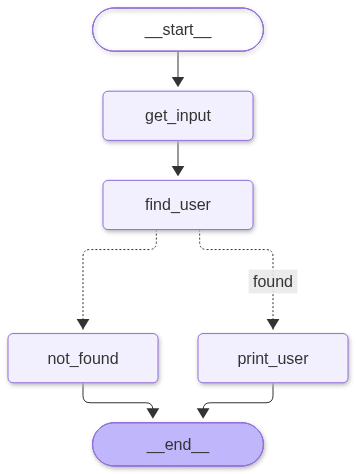

In [53]:
#Print Graph
display(
    Image(workflow.get_graph().draw_mermaid_png())
)

In [54]:
result = workflow.invoke({
    "input": 5
})


User with ID 5 not found.
